In [1]:
import os
from collections import defaultdict
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [12]:
folder = 'train'

LABELS_DIR = f"/Users/mzhai72/Desktop/SC-RNA Seq/CFU-classifier/data/split_AI/{folder}/labels"
IMAGES_DIR = f"/Users/mzhai72/Desktop/SC-RNA Seq/CFU-classifier/data/split_AI/{folder}/images"
SUPPORTED_IMG = {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp"}

# Load class names
classes_path = os.path.join(LABELS_DIR, "classes.txt")
with open(classes_path) as f:
    classes = [line.strip() for line in f if line.strip()]
print(f"Classes ({len(classes)}): {classes}")

# Find all images in the train folder
all_images = [
    f for f in os.listdir(IMAGES_DIR)
    if os.path.splitext(f)[1].lower() in SUPPORTED_IMG
]

# Parse all annotation files
counts_per_class = defaultdict(int)   # total boxes per class
images_per_class = defaultdict(set)   # which images contain each class
annotated_images = set()
unannotated_images = []

for img_file in all_images:
    stem = os.path.splitext(img_file)[0]
    txt_path = os.path.join(LABELS_DIR, stem + ".txt")

    if not os.path.exists(txt_path):
        unannotated_images.append(img_file)
        continue

    with open(txt_path) as f:
        lines = [l.strip() for l in f if l.strip()]

    if not lines:
        unannotated_images.append(img_file)
        continue

    annotated_images.add(img_file)
    for line in lines:
        idx = int(line.split()[0])
        counts_per_class[idx] += 1
        images_per_class[idx].add(img_file)

print(f"\nAnnotated:   {len(annotated_images)} / {len(all_images)} images")
print(f"Unannotated: {len(unannotated_images)} images")

Classes (4): ['BFU', 'GM', 'E', 'GEMM']

Annotated:   29 / 30 images
Unannotated: 1 images


In [21]:
# --- Summary table ---
print(f"{'Class':<12} {'Total boxes':>12} {'Images containing':>18}")
print("-" * 44)
for idx, name in enumerate(classes):
    boxes = counts_per_class.get(idx, 0)
    imgs  = len(images_per_class.get(idx, set()))
    print(f"{name:<12} {boxes:>12} {imgs:>18}")

Class         Total boxes  Images containing
--------------------------------------------
BFU                   651                 28
GM                   1815                 29
E                     178                 25
GEMM                   17                 10


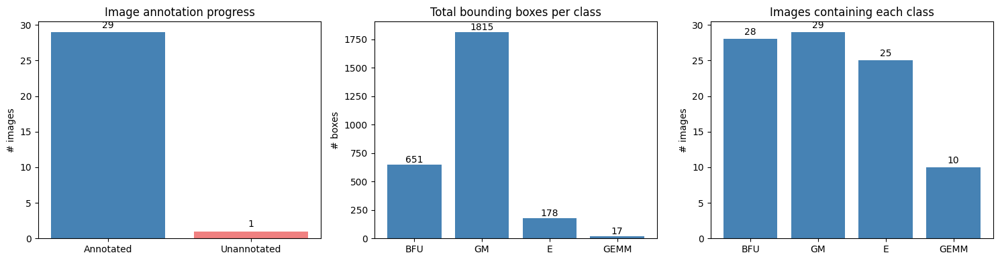

In [22]:
# --- Bar charts ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Annotation progress
ax = axes[0]
ax.bar(["Annotated", "Unannotated"], [len(annotated_images), len(unannotated_images)],
       color=["steelblue", "lightcoral"])
ax.set_title("Image annotation progress")
ax.set_ylabel("# images")
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(bar.get_height())), ha="center", va="bottom")

# 2. Total boxes per class
ax = axes[1]
names  = [classes[i] for i in range(len(classes))]
totals = [counts_per_class.get(i, 0) for i in range(len(classes))]
bars = ax.bar(names, totals, color="steelblue")
ax.set_title("Total bounding boxes per class")
ax.set_ylabel("# boxes")
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(bar.get_height())), ha="center", va="bottom")

# 3. Images containing each class
ax = axes[2]
img_counts = [len(images_per_class.get(i, set())) for i in range(len(classes))]
bars = ax.bar(names, img_counts, color="steelblue")
ax.set_title("Images containing each class")
ax.set_ylabel("# images")
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(bar.get_height())), ha="center", va="bottom")

plt.tight_layout()
plt.show()

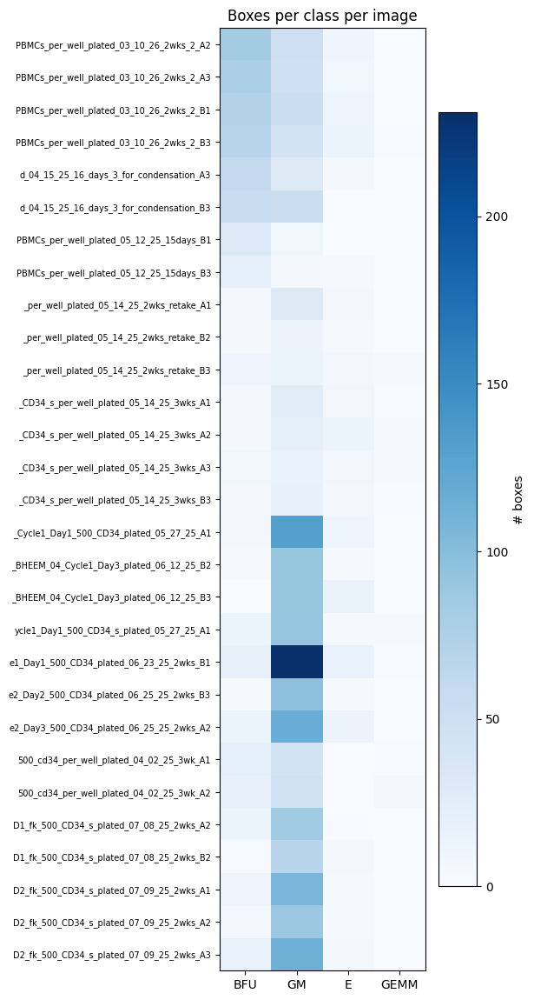

In [15]:
# --- Per-image breakdown ---
# Shows a heatmap of which classes appear in each annotated image
if annotated_images:
    img_list = sorted(annotated_images)
    matrix = []
    for img in img_list:
        row = []
        stem = os.path.splitext(img)[0]
        txt_path = os.path.join(LABELS_DIR, stem + ".txt")
        class_counts = defaultdict(int)
        with open(txt_path) as f:
            for line in f:
                line = line.strip()
                if line:
                    class_counts[int(line.split()[0])] += 1
        for idx in range(len(classes)):
            row.append(class_counts.get(idx, 0))
        matrix.append(row)

    fig, ax = plt.subplots(figsize=(max(6, len(classes) * 1.5), max(4, len(img_list) * 0.4)))
    im = ax.imshow(matrix, aspect="auto", cmap="Blues")
    ax.set_xticks(range(len(classes)))
    ax.set_xticklabels(classes)
    ax.set_yticks(range(len(img_list)))
    ax.set_yticklabels([os.path.splitext(f)[0][-40:] for f in img_list], fontsize=7)
    ax.set_title("Boxes per class per image")
    plt.colorbar(im, ax=ax, label="# boxes")
    plt.tight_layout()
    plt.show()

In [16]:
# --- Unannotated images ---
if unannotated_images:
    print(f"{len(unannotated_images)} unannotated image(s):")
    for f in sorted(unannotated_images):
        print(" ", f)
else:
    print("All images are annotated!")

1 unannotated image(s):
  2025_04_23_S1_01_PBXT0_500_PBMCs_per_well_plated_04_02_25_3wk_B1.jpg


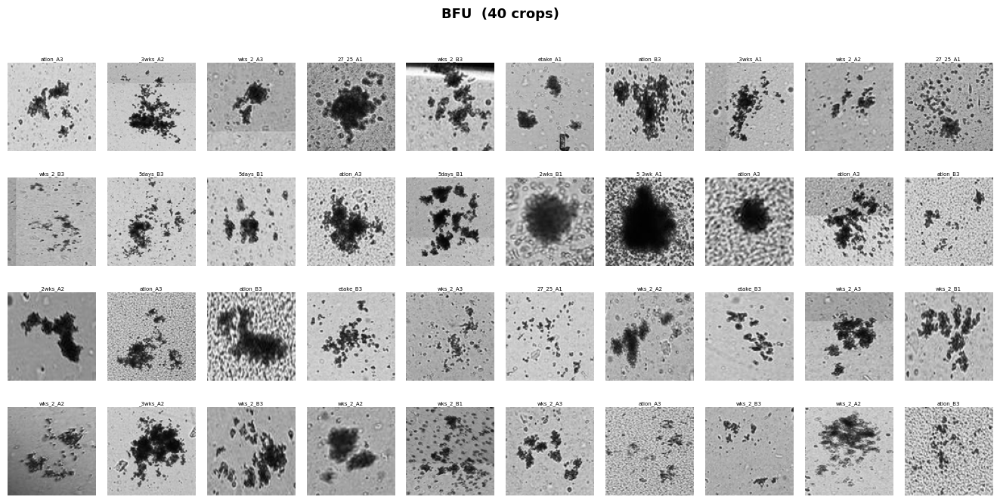

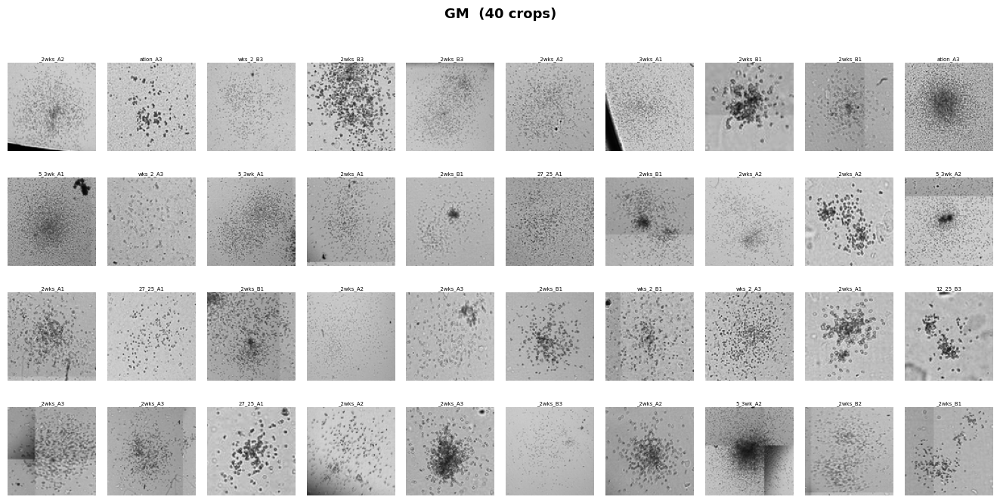

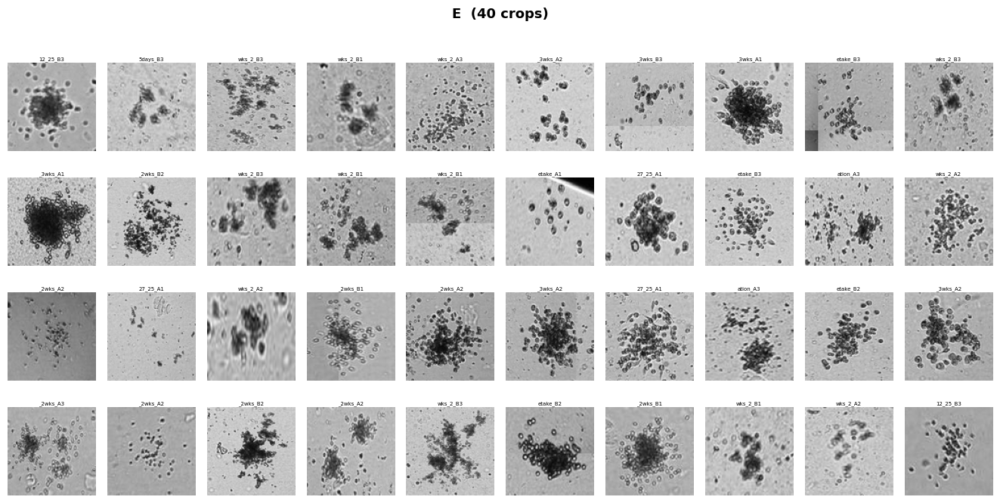

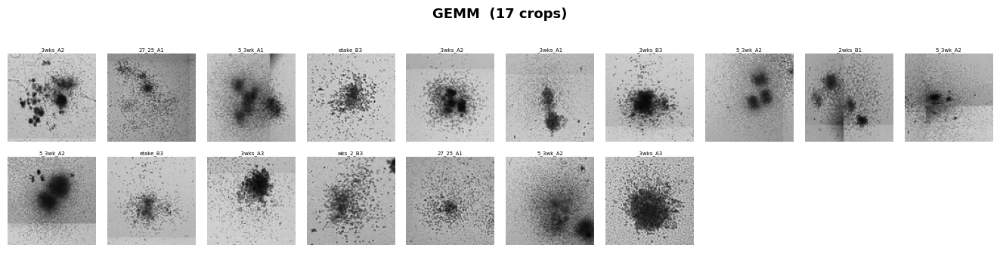

In [17]:
import random
from PIL import Image as PILImage
import numpy as np

def get_crops(class_idx, max_crops=40, min_px=10):
    """Returns up to max_crops (crop, short_label) tuples for the given class index."""
    crops = []
    for img_file in sorted(images_per_class.get(class_idx, [])):
        stem = os.path.splitext(img_file)[0]
        txt_path = os.path.join(LABELS_DIR, stem + ".txt")
        img_path = os.path.join(IMAGES_DIR, img_file)

        # Use the last 8 chars of the stem as a short label (e.g. "2wks_A2")
        short_label = stem[-8:]

        img = PILImage.open(img_path)
        W, H = img.size

        with open(txt_path) as f:
            for line in f:
                parts = line.strip().split()
                if not parts or int(parts[0]) != class_idx:
                    continue
                _, xc, yc, w, h = map(float, parts)
                x1 = int((xc - w / 2) * W)
                y1 = int((yc - h / 2) * H)
                x2 = int((xc + w / 2) * W)
                y2 = int((yc + h / 2) * H)
                x1, y1 = max(0, x1), max(0, y1)
                x2, y2 = min(W, x2), min(H, y2)
                if (x2 - x1) < min_px or (y2 - y1) < min_px:
                    continue
                crops.append((img.crop((x1, y1, x2, y2)), short_label))

    random.shuffle(crops)
    return crops[:max_crops]


def show_mosaic(class_idx, class_name, max_crops=40, thumb_size=96, cols=10):
    crops = get_crops(class_idx, max_crops=max_crops)
    if not crops:
        print(f"{class_name}: no crops found")
        return

    rows = (len(crops) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols,
                             figsize=(cols * (thumb_size / 72), rows * (thumb_size / 72 + 0.35)))
    fig.suptitle(f"{class_name}  ({len(crops)} crops)", fontsize=13, fontweight="bold", y=1.01)

    axes = np.array(axes).reshape(rows, cols)
    for i, (crop, label) in enumerate(crops):
        r, c = divmod(i, cols)
        ax = axes[r, c]
        ax.imshow(np.array(crop.resize((thumb_size, thumb_size), PILImage.LANCZOS)))
        ax.set_title(label, fontsize=5, pad=2)
        ax.axis("off")

    # Hide any unused subplots
    for j in range(len(crops), rows * cols):
        r, c = divmod(j, cols)
        axes[r, c].axis("off")

    plt.tight_layout()
    plt.show()


# --- Show mosaic for every class ---
for idx, name in enumerate(classes):
    show_mosaic(idx, name)

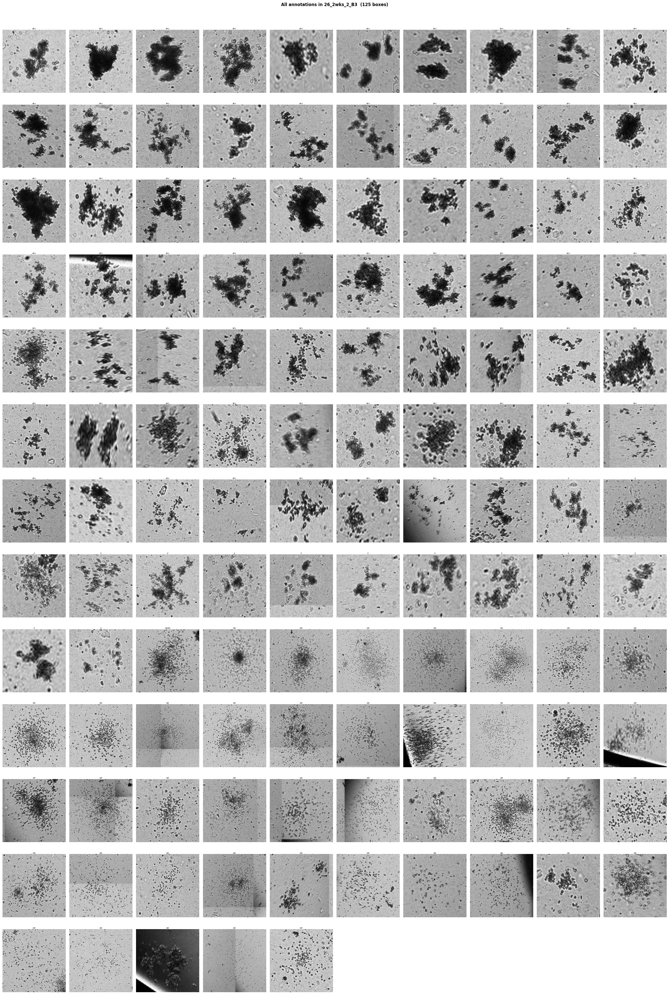

In [25]:
images = [f for f in os.listdir(IMAGES_DIR) if os.path.splitext(f)[1].lower() in SUPPORTED_IMG]

# --- Single-image mosaic for verification ---
VERIFY_IMAGE = images[0] # Just pick the first image for verification
thumb_size = 192
cols = 10

stem = os.path.splitext(VERIFY_IMAGE)[0]
txt_path = os.path.join(LABELS_DIR, stem + ".txt")
img_path = os.path.join(IMAGES_DIR, VERIFY_IMAGE)

img = PILImage.open(img_path)
W, H = img.size

crops = []  # (crop, class_name)
with open(txt_path) as f:
    for line in f:
        parts = line.strip().split()
        if not parts:
            continue
        idx = int(parts[0])
        _, xc, yc, w, h = map(float, parts)
        x1 = max(0, int((xc - w / 2) * W))
        y1 = max(0, int((yc - h / 2) * H))
        x2 = min(W, int((xc + w / 2) * W))
        y2 = min(H, int((yc + h / 2) * H))
        if (x2 - x1) < 10 or (y2 - y1) < 10:
            continue
        crops.append((img.crop((x1, y1, x2, y2)), classes[idx]))

# Sort by class name so all GMs together, all BFUs together, etc.
crops.sort(key=lambda x: x[1])

rows = (len(crops) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols,
                         figsize=( cols * (thumb_size / 72),rows * (thumb_size / 72 + 0.35)))
fig.suptitle(f"All annotations in {stem[-12:]}  ({len(crops)} boxes)", fontsize=12, fontweight="bold", y=1.01)

axes = np.array(axes).reshape(rows, cols)
for i, (crop, label) in enumerate(crops):
    r, c = divmod(i, cols)
    ax = axes[r, c]
    ax.imshow(np.array(crop.resize((thumb_size, thumb_size), PILImage.LANCZOS)))
    ax.set_title(label, fontsize=5, pad=2)
    ax.axis("off")

for j in range(len(crops), rows * cols):
    r, c = divmod(j, cols)
    axes[r, c].axis("off")

plt.tight_layout() 
plt.show()

In [ ]:

t

['03_24_26_S1_05_PB0_100k_PBMCs_per_well_plated_03_10_26_2wks_2_B3.jpg',
 '05_27_25_S1_03_PB0_100k_PBMCs_per_well_plated_05_12_25_15days_B3.jpg',
 '05_27_25_S1_03_PB0_100k_PBMCs_per_well_plated_05_12_25_15days_B1.jpg',
 '03_24_26_S1_05_PB0_100k_PBMCs_per_well_plated_03_10_26_2wks_2_B1.jpg',
 '2025_07_22_S1_01_mPB1_D1_fk_500_CD34_s_plated_07_08_25_2wks_A2.jpg',
 '2025_04_23_S1_01_PBXT0_500_cd34_per_well_plated_04_02_25_3wk_A1.jpg',
 '05_01_25_S1_02_PB0_100k_PBMCs_per_well_plated_04_15_25_16_days_3_for_condensation_A3.jpg',
 '07_08_25_BHEEM_04_Cycle2_Day2_500_CD34_plated_06_25_25_2wks_B3.jpg',
 '2025_04_23_S1_01_PBXT0_500_cd34_per_well_plated_04_02_25_3wk_A2.jpg',
 '06_04_25_S1_03_BM0_500_CD34_s_per_well_plated_05_14_25_3wks_A3.jpg',
 '06_04_25_S1_03_BM0_500_CD34_s_per_well_plated_05_14_25_3wks_A2.jpg',
 '05_28_25_S1_03_PB0_500_CD34_s_per_well_plated_05_14_25_2wks_retake_B3.jpg',
 '06_04_25_S1_03_BM0_500_CD34_s_per_well_plated_05_14_25_3wks_A1.jpg',
 '05_28_25_S1_03_PB0_500_CD34_s_per_we